# Statistical Evaluation of Metabolic and Demographic Covariates in Type 2 Diabetes Diagnosis
## Data Cleaning and Exploratory Analysis of the Pima Indians Diabetes Cohort
  
**Dataset:** National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK)

### Abstract & Introduction
The primary aim of this study is to analyze and quantify the relationship between key metabolic biomarkers and diagnostic outcomes of Type 2 diabetes mellitus in Pima Indian population groups.  To achieve this, I have incorporated a python based computational workflow to examine physiological risk factors associated with diabetes. Utilizing data from the historical Pima Indians Diabetes database, this analysis details data-cleaning methodology designed to identify and isolate unrecorded physiological values hidden as structural zero-placeholders.

Following systematic data validation, the project evaluates cohort-level variations in plasma glucose, BMI, and age distributions between diagnostic groups. This study applies standard statistical evaluations such as Welch’s t-tests, Chi-Square tests of independence, and standardized effect size calculations to determine the statistical inferences.

Steps include:
1. Execution through raw data loading mirrors and deterministic assertion validation.
2. Isolating physiologically impossible null values such as numeric zeros to mitigate downstream bias.
3. Applying independent-sample hypothesis tests without assuming equal population variances, paired with non-parametric association tests for binned demographic cohorts.
4. Computing Cohen's $d$ metrics to decouple clinical significance from simple sample-size-driven statistical significance.

In [1]:
# 0. Setup: imports and reproducibility
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

print("Setup done.")

Setup done.


## 1 · Loading the data

We load the Pima Indians Diabetes dataset from GitHub, assign descriptive column names, and validate that the data matches the expected structure of 768 observations and 9 variables. A preview of the initial records confirms the import was successful.



In [2]:
import pandas as pd

COLS = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
        "insulin", "bmi", "pedigree", "age", "outcome"]
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

def load_pima():
    """Load the Pima diabetes data from the primary mirror."""
    df = pd.read_csv(URL, header=None, names=COLS)
    print(f"Successfully loaded from: {URL}")
    return df

df_raw = load_pima()
assert df_raw.shape == (768, 9), f"Unexpected shape: {df_raw.shape}"
print("Shape (rows, columns):", df_raw.shape)
df_raw.head(8)

Successfully loaded from: https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv
Shape (rows, columns): (768, 9)


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0


## 2 · Inspecting the Raw Data

In this step, we are looking for three specific issues:
1. **Data Types**: Ensuring columns loaded with the correct numeric or categorical types.
2. **Impossible Zeros**: In this cohort, values of `0` for attributes like blood pressure, BMI, or glucose are physiologically impossible. They actually represent missing records rather than actual zero measurements.
3. **Duplicate Rows**: Checking for redundant entries that could skew our statistics.

In [3]:

ZERO_MEANS_MISSING = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]

print("--- Data types ---")
print(df_raw.dtypes)

print("\n--- Missing values ---")
for col in ZERO_MEANS_MISSING:  # loop over the suspect columns
    n_zero = int((df_raw[col] == 0).sum())  # count the zeros
    print(f"{col}: {n_zero} zeros ({n_zero / len(df_raw):.1%} of patients)")

print("\nDuplicated rows:", int(df_raw.duplicated().sum()))
print("Diabetes rate:", f"{df_raw['outcome'].mean():.1%}")

--- Data types ---
pregnancies         int64
glucose             int64
blood_pressure      int64
skin_thickness      int64
insulin             int64
bmi               float64
pedigree          float64
age                 int64
outcome             int64
dtype: object

--- Missing values ---
glucose: 5 zeros (0.7% of patients)
blood_pressure: 35 zeros (4.6% of patients)
skin_thickness: 227 zeros (29.6% of patients)
insulin: 374 zeros (48.7% of patients)
bmi: 11 zeros (1.4% of patients)

Duplicated rows: 0
Diabetes rate: 34.9%


## 3 · Cleaning the Dataset


We first convert the biological impossible `0`s into actual `NaN` values, and then filter the dataset down to complete records. We also use `assert` statements at the end of each task. This way, if anything goes wrong during cleaning, Python will immediately stop to pinpoint the issue.

In [4]:
#  Turn impossible zeros into missing values
def mark_missing(df, columns):
    """Replace biologically impossible 0s with NaN (pandas' 'missing' marker)."""
    df = df.copy()  # to keep source intact
    for col in columns:
        df.loc[df[col] == 0, col] = np.nan
    return df

# Test the function on a tiny example BEFORE trusting it on real data
tiny = pd.DataFrame({"glucose": [120, 0], "age": [33, 40]})
assert mark_missing(tiny, ["glucose"])["glucose"].isna().sum() == 1
assert (mark_missing(tiny, ["glucose"])["age"] == [33, 40]).all()
print("Function tests passed.")

df = mark_missing(df_raw, ZERO_MEANS_MISSING)
print("Missing values after marking:")
print(df[ZERO_MEANS_MISSING].isna().sum())

Function tests passed.
Missing values after marking:
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
dtype: int64


In [5]:

n_before = len(df)
df_clean = df.dropna(subset=ZERO_MEANS_MISSING).reset_index(drop=True)
print(f"Dropped {n_before - len(df_clean)} rows with missing measurements.")
print(f"Clean dataset: {len(df_clean)} patients.")

# Validation checks
assert df_clean.duplicated().sum() == 0, "duplicates remain!"
assert df_clean[ZERO_MEANS_MISSING].isna().sum().sum() == 0, "missing values remain!"
assert (df_clean[ZERO_MEANS_MISSING] > 0).all().all(), "impossible value survived!"
print("All checks passed.")
df_clean.head(5)

Dropped 376 rows with missing measurements.
Clean dataset: 392 patients.
All checks passed.


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
0,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
1,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1
2,3,78.0,50.0,32.0,88.0,31.0,0.248,26,1
3,2,197.0,70.0,45.0,543.0,30.5,0.158,53,1
4,1,189.0,60.0,23.0,846.0,30.1,0.398,59,1


## 4 · Visualizing and Summarizing our Cleaned Data

Before grouping, we create a simple helper function to bin patients into two age groups: patients under 40 and 40+.

 -Running a summary table using `groupby` to generate two plots and compare glucose levels between patients with and without diabetes.

        glucose                bmi              age            
          count   mean   std count  mean  std count  mean   std
outcome                                                        
0           262  111.4  24.6   262  31.8  6.8   262  28.3   9.0
1           130  145.2  29.8   130  35.8  6.7   130  35.9  10.6

Outcome counts: {0: 262, 1: 130} (0 = no diabetes, 1 = diabetes)


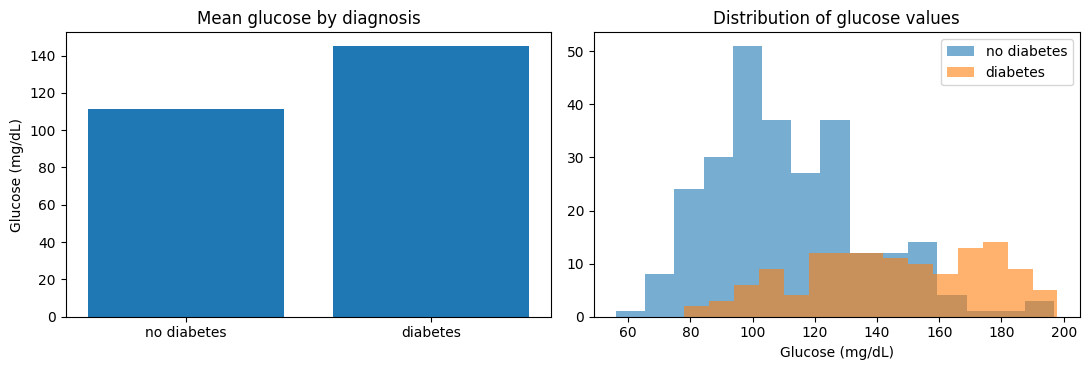

In [6]:
# 4. New column (if/else) + group summaries + charts
def age_group(age):
    if age < 40:
        return "under 40"
    else:
        return "40 plus"

assert age_group(33) == "under 40" and age_group(55) == "40 plus"
df_clean["age_group"] = df_clean["age"].apply(age_group)

grouped_data = df_clean.groupby("outcome")[["glucose", "bmi", "age"]]
summary = grouped_data.agg(["count", "mean", "std"])
summary = summary.round(1)

print(summary)
print("\nOutcome counts:", df_clean["outcome"].value_counts().to_dict(),
      "(0 = no diabetes, 1 = diabetes)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
# Chart 1: average glucose per group (bar chart)
means = df_clean.groupby("outcome")["glucose"].mean()
ax[0].bar(["no diabetes", "diabetes"], means.values)
ax[0].set_title("Mean glucose by diagnosis")
ax[0].set_ylabel("Glucose (mg/dL)")
# Chart 2: spread of glucose (histogram, one color per group)
for label, sub in df_clean.groupby("outcome"):
    name = "diabetes" if label == 1 else "no diabetes"
    ax[1].hist(sub["glucose"], bins=15, alpha=0.6, label=name)
ax[1].set_title("Distribution of glucose values")
ax[1].set_xlabel("Glucose (mg/dL)")
ax[1].legend()
fig.tight_layout()
plt.show()

## 5 · Statistical Testing: Glucose Levels (t-test)

Now we want to see if the differences we observed in our plots are mathematically meaningful or just due to random noise.

Next, we'll run a **Welch's t-test** to compare average glucose levels between the two groups. This test is a reliable default because it does not assume both groups have the exact same variance. A standard threshold of `p < 0.05` will tell us if the gap is statistically significant.

In [7]:
#5. Welch t-test on glucose
diab = df_clean.loc[df_clean["outcome"] == 1, "glucose"]
nondiab = df_clean.loc[df_clean["outcome"] == 0, "glucose"]

t_stat, p_value = stats.ttest_ind(diab, nondiab, equal_var=False)
diff = diab.mean() - nondiab.mean()

print(f"Diabetes group: mean {diab.mean():.1f} (SD {diab.std():.1f}, n={len(diab)})")
print(f"No-diabetes group: mean {nondiab.mean():.1f} (SD {nondiab.std():.1f}, n={len(nondiab)})")
print(f"Difference: {diff:.1f} mg/dL")
print(f"t = {t_stat:.2f}, p = {p_value:.4f}")

if p_value < 0.05:
    print("→ p < 0.05: the difference is statistically significant (unlikely to be luck).")
else:
    print("→ p ≥ 0.05: not significant — the gap could plausibly be chance.")

Diabetes group: mean 145.2 (SD 29.8, n=130)
No-diabetes group: mean 111.4 (SD 24.6, n=262)
Difference: 33.8 mg/dL
t = 11.15, p = 0.0000
→ p < 0.05: the difference is statistically significant (unlikely to be luck).


## 6 · Statistical Testing: Age Group vs. Diagnosis (Chi-Square)

Our previous test looked at continuous measurements (glucose numbers). Now we want to shift our focus to categorical variables: does a patient's age group (under 40 vs. 40+) have a meaningful relationship with their diabetes status?

To find out, we will:
1. Build a contingency table (cross-tabulation) to see the actual overlap counts between age groups and outcomes.
2. Run a **Chi-Square Test of Independence** to check if the patterns we see are statistically significant or just random variation.

In [8]:
#6. Chi-square test on age group vs diagnosis
table = pd.crosstab(df_clean["age_group"], df_clean["outcome"])
table.columns = ["no diabetes", "diabetes"]
print(table)

chi2, p_chi, dof, expected = stats.chi2_contingency(table)
print(f"\nchi² = {chi2:.2f}, p = {p_chi:.4f} (degrees of freedom = {dof})")

if p_chi < 0.05:
    print("→ p < 0.05: diagnosis is significantly linked to age group.")
else:
    print("→ p ≥ 0.05: no significant link — the pattern could be chance.")

           no diabetes  diabetes
age_group                       
40 plus             29        47
under 40           233        83

chi² = 33.40, p = 0.0000 (degrees of freedom = 1)
→ p < 0.05: diagnosis is significantly linked to age group.


## 7 · Effect Size and Practical Significance

A small p-value confirms that our results are unlikely to be due to random variation, but it doesn't measure physical impact. To understand how large or clinically meaningful the differences actually are, we need to calculate the **effect size** using **Cohen's d** (where a value of ~0.2 is considered small, ~0.5 is medium, and ~0.8 or higher is large).

To wrap up our analysis, we will:
1. Run our helper function to compute Cohen's d for glucose levels between the two diagnosis groups.
2. Translate the statistical findings into a meaningful summary.

In [9]:
#7. Effect size + plain-language conclusion
def cohens_d(group1, group2):
    """Standardized difference between two groups' means."""
    n1, n2 = len(group1), len(group2)
    pooled_sd = np.sqrt(((n1 - 1) * group1.var() + (n2 - 1) * group2.var()) / (n1 + n2 - 2))
    return (group1.mean() - group2.mean()) / pooled_sd

d = cohens_d(diab, nondiab)
print(f"Cohen's d = {d:.2f}")
print(f"\nIn plain language: patients with diabetes averaged ~{diff:.0f} mg/dL higher glucose "
      f"(p={p_value:.4f}, d={d:.2f}) — a real and large gap, as expected for a diagnostic marker.")

Cohen's d = 1.28

In plain language: patients with diabetes averaged ~34 mg/dL higher glucose (p=0.0000, d=1.28) — a real and large gap, as expected for a diagnostic marker.


### Limitations
- **Potential Selection Bias due to Complete-Case Analysis:** Restricting the sample to complete cases resulted in the exclusion of approximately half of the original cohort, primarily due to missing insulin and skinfold thickness measurements. If this missingness is systematic rather than completely at random, it may introduce selection bias. Future iterations should evaluate imputation strategies, such as median or multiple imputation, to preserve statistical power.
- **Generalizability (External Validity):** This cohort consists exclusively of Pima Indian women aged 21 and older. Consequently, the findings and diagnostic distributions may not generalize to other demographic groups, genders, or ethnic backgrounds.
- **Observational and Cross-Sectional Constraints:** Because this analysis is based on observational, cross-sectional data, we cannot establish temporal causality. Furthermore, elevated plasma glucose is itself a primary diagnostic criterion for diabetes; therefore, the strong association observed in our t-test validates a known clinical marker rather than establishing a novel predictive relationship.

### Key Takeaways and Methodology Insights
This investigation demonstrates that systematic raw data auditing is crucial for clinical dataset preparation, as seen in the identification of unrecorded physiological values disguised as structural zeros. By implementing defensive programming with deterministic assertions, we can establish rigorous verification checks that prevent downstream analytical errors. Ultimately, decoupling statistical significance from practical effects through effect-size quantification like Cohen's $d$ allows researchers to capture the clinical magnitude of diagnostic variables rather than relying solely on sample-size-dependent p-values.

### Data source
Smith, J.W. et al. (1988). *Using the ADAP learning algorithm to forecast the onset of diabetes mellitus.* Johns Hopkins APL Technical Digest 9, 6–12. Via the UCI Machine Learning Repository (public mirrors loaded above).